<a href="https://colab.research.google.com/github/VincentArfan/Prediksi-Deposito-Bank/blob/main/Salinan_dari_DeepLearning_UTS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Keberhasilan Pemasaran Bank Menggunakan Multi-Layer Perceptron (MLP)

In [1]:
!pip install ucimlrepo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ucimlrepo import fetch_ucirepo

In [3]:
keras.utils.set_random_seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


Import Dataset

In [4]:
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features.copy()
y = bank_marketing.data.targets['y'].copy()

y = (y == 'yes').astype(int)

df = X.copy()
df['target'] = y

print(f"Total Baris: {df.shape[0]}, Total Kolom Awal: {df.shape[1]}")
df.head()

Total Baris: 45211, Total Kolom Awal: 17


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,target
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,0
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,0
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,0
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,0


Analisis Masalah

In [5]:
# Mengecek rasio/distribusi kelas target untuk membuktikan ketidakseimbangan data
target_counts = df['target'].value_counts(normalize=True) * 100
print("Persentase Distribusi Kelas Target:")
print(target_counts)

# Memeriksa tipe data setiap kolom untuk menunjukkan variasi tipe data
print("Tipe Data per Kolom:")
print(df.dtypes)

# Melihat jumlah kolom kategorikal yang memerlukan encoding
cat_cols = df.select_dtypes(include=['object', 'category']).columns
print(f"\nJumlah kolom kategorikal yang harus di-encode: {len(cat_cols)}")

# Memeriksa korelasi fitur terhadap target sebelum pembersihan
# (Menunjukkan mengapa fitur seperti 'duration' harus diwaspadai/dihapus)
numeric_cols = df.select_dtypes(include=['number']).columns
if 'target' in df.columns:
    correlations = df[numeric_cols].corr()['target'].sort_values(ascending=False)
    print("Korelasi Fitur Numerik terhadap Target:")
    print(correlations)

# Memeriksa statistik deskriptif untuk melihat rentang nilai dan variasi sebaran data
print("Statistik Deskriptif Fitur Numerik:")
print(df.describe())

Persentase Distribusi Kelas Target:
target
0    88.30152
1    11.69848
Name: proportion, dtype: float64
Tipe Data per Kolom:
age             int64
job            object
marital        object
education      object
default        object
balance         int64
housing        object
loan           object
contact        object
day_of_week     int64
month          object
duration        int64
campaign        int64
pdays           int64
previous        int64
poutcome       object
target          int64
dtype: object

Jumlah kolom kategorikal yang harus di-encode: 9
Korelasi Fitur Numerik terhadap Target:
target         1.000000
duration       0.394521
pdays          0.103621
previous       0.093236
balance        0.052838
age            0.025155
day_of_week   -0.028348
campaign      -0.073172
Name: target, dtype: float64
Statistik Deskriptif Fitur Numerik:
                age        balance   day_of_week      duration      campaign  \
count  45211.000000   45211.000000  45211.000000  45211.0000

Data Exploration & Check Missing Value

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. Hapus kolom 'duration' untuk mencegah data leakage
print(df.columns)
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])
    print("Berhasil menghapus kolom 'duration'.")

# 2. Pisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['target'])
y = df['target']

# 3. Lakukan Train-Test Split (Gunakan stratify=y agar proporsi kelas seimbang)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Sekarang y_train sudah ada, hitung Class Weights dengan aman
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Bobot Kelas (Class Weights) berhasil dihitung:", class_weight_dict)

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign',
       'pdays', 'previous', 'poutcome', 'target'],
      dtype='object')
Berhasil menghapus kolom 'duration'.
Bobot Kelas (Class Weights) berhasil dihitung: {0: np.float64(0.5662397845758838), 1: np.float64(4.27416686362562)}


Pembagian Data (70% Train, 15% Validation, 15% Test)

In [7]:
# Mengulangi pembagian data sesuai spesifikasi laporan (70% Train, 15% Val, 15% Test)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Membagi sisa 85% data menjadi 70% Train dan 15% Validation (15/85 = 0.1764)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.17647, random_state=42, stratify=y_train_full
)

print(f"Jumlah Data Latih (Train): {X_train.shape[0]} ({(X_train.shape[0]/len(df))*100:.1f}%)")
print(f"Jumlah Data Validasi (Val): {X_val.shape[0]} ({(X_val.shape[0]/len(df))*100:.1f}%)")
print(f"Jumlah Data Uji (Test): {X_test.shape[0]} ({(X_test.shape[0]/len(df))*100:.1f}%)")

# Hitung ulang Class Weights untuk data latih baru
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("\nBobot Kelas (Class Weights):", class_weight_dict)

Jumlah Data Latih (Train): 31647 (70.0%)
Jumlah Data Validasi (Val): 6782 (15.0%)
Jumlah Data Uji (Test): 6782 (15.0%)

Bobot Kelas (Class Weights): {0: np.float64(0.5662575150300602), 1: np.float64(4.273156899810964)}


Preprocessing Data (Encoding & Scaling)

In [8]:
# One-Hot Encoding
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
# Menyelaraskan kolom Validasi dan Test agar sama dengan Train
X_val_encoded = pd.get_dummies(X_val, drop_first=True).reindex(columns=X_train_encoded.columns, fill_value=0)
X_test_encoded = pd.get_dummies(X_test, drop_first=True).reindex(columns=X_train_encoded.columns, fill_value=0)

# Standarisasi (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_val_scaled = scaler.transform(X_val_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print(f"Dimensi fitur setelah preprocessing: {X_train_scaled.shape[1]} kolom")
# Ini akan menghasilkan 37 kolom yang sesuai dengan arsitektur di laporan

Dimensi fitur setelah preprocessing: 37 kolom


Membangun Arsitektur MLP

In [9]:
def build_tuned_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),

        layers.Dense(64, activation='relu', name='dense_1'),
        layers.BatchNormalization(name='batch_norm_1'),
        layers.Dropout(0.3, name='dropout_1'),

        layers.Dense(32, activation='relu', name='dense_2'),
        layers.BatchNormalization(name='batch_norm_2'),
        layers.Dropout(0.2, name='dropout_2'),

        layers.Dense(16, activation='relu', name='dense_3'),

        layers.Dense(1, activation='sigmoid', name='output')
    ])
    return model

model = build_tuned_model(X_train_scaled.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 192 (768.00 B)

Pelatihan Model

In [10]:
# Kompilasi model
optimizer = keras.optimizers.Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Setup Callback
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True
)

# Pelatihan Model
history = model.fit(
    X_train_scaled, y_train,
    epochs=40,
    batch_size=64,
    validation_data=(X_val_scaled, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6214 - loss: 0.6623 - val_accuracy: 0.7943 - val_loss: 0.5572
Epoch 2/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7193 - loss: 0.6145 - val_accuracy: 0.8054 - val_loss: 0.5577
Epoch 3/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7404 - loss: 0.6015 - val_accuracy: 0.8026 - val_loss: 0.5515
Epoch 4/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7418 - loss: 0.5963 - val_accuracy: 0.7990 - val_loss: 0.5517
Epoch 5/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7580 - loss: 0.5880 - val_accuracy: 0.7965 - val_loss: 0.5511
Epoch 6/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7610 - loss: 0.5838 - val_accuracy: 0.8008 - val_loss: 0.5491
Epoch 7/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7612 - loss: 0.5822 - val_accuracy: 0.8017 - val_loss: 0.5470
Epoch 8/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7695 - loss: 0.5787 - val_accuracy: 0

Evaluasi dan Grafik

212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
=== Hasil Evaluasi Data Testing ===
Accuracy     : 0.8172
Precision    : 0.3316
Recall       : 0.5549
F1-Score     : 0.4151
ROC-AUC      : 0.7659

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.85      0.89      5989
           1       0.33      0.55      0.42       793

    accuracy                           0.82      6782
   macro avg       0.63      0.70      0.65      6782
weighted avg       0.86      0.82      0.84      6782



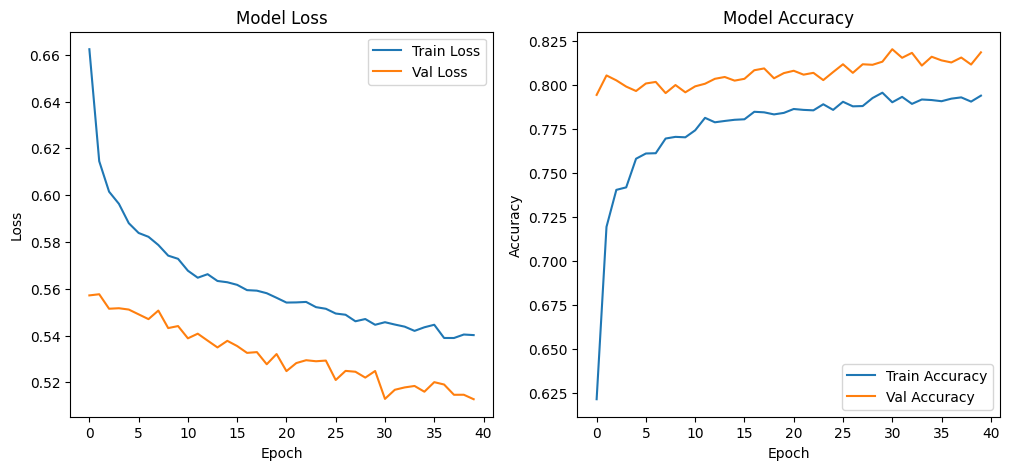

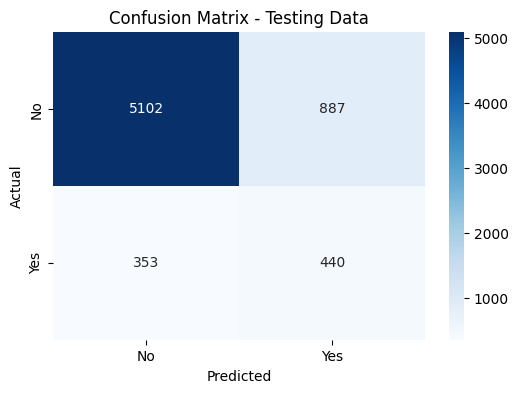

In [11]:
# Prediksi probabilitas dan label kelas
y_pred_probs = model.predict(X_test_scaled).flatten()
y_pred = (y_pred_probs > 0.5).astype(int)

# Metrik Evaluasi
acc = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, pos_label=1, average='binary')
roc_auc = roc_auc_score(y_test, y_pred_probs)

print("=== Hasil Evaluasi Data Testing ===")
print(f"Accuracy     : {acc:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"F1-Score     : {f1:.4f}")
print(f"ROC-AUC      : {roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot Learning Curve (Loss & Accuracy)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Loss
ax[0].plot(history.history['loss'], label='Train Loss')
ax[0].plot(history.history['val_loss'], label='Val Loss')
ax[0].set_title('Model Loss')
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

# Accuracy
ax[1].plot(history.history['accuracy'], label='Train Accuracy')
ax[1].plot(history.history['val_accuracy'], label='Val Accuracy')
ax[1].set_title('Model Accuracy')
ax[1].set_ylabel('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.show()

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title('Confusion Matrix - Testing Data')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Fitur Unik ke-2: Tuning Threshold Keputusan

In [12]:
# Mencari threshold optimal pada data validasi
val_probs = model.predict(X_val_scaled).flatten()
thresholds = np.arange(0.1, 0.9, 0.05)
best_threshold = 0.5
best_f1 = 0

for t in thresholds:
    val_preds_t = (val_probs > t).astype(int)
    _, _, f1_t, _ = precision_recall_fscore_support(y_val, val_preds_t, pos_label=1, average='binary', zero_division=0)
    if f1_t > best_f1:
        best_f1 = f1_t
        best_threshold = t

print(f"Threshold optimal berdasarkan Validation Data: {best_threshold:.2f}")

# Terapkan threshold optimal ke Data Testing
y_pred_tuned = (y_pred_probs > best_threshold).astype(int)
precision_t, recall_t, f1_t, _ = precision_recall_fscore_support(y_test, y_pred_tuned, pos_label=1, average='binary')

print("\n=== Hasil Setelah Threshold Tuning ===")
print(f"Precision    : {precision_t:.4f}")
print(f"Recall       : {recall_t:.4f}")
print(f"F1-Score     : {f1_t:.4f}")

212/212 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Threshold optimal berdasarkan Validation Data: 0.65

=== Hasil Setelah Threshold Tuning ===
Precision    : 0.4376
Recall       : 0.4641
F1-Score     : 0.4504


In [20]:
import pandas as pd
import numpy as np

# 1. Buat data sampel (input) baru dalam bentuk Dictionary
# Pastikan fitur yang dimasukkan sesuai dengan data asli, TANPA kolom 'duration' dan 'target'
data_input = {
    'age': [35],
    'job': ['management'],
    'marital': ['single'],
    'education': ['tertiary'],
    'default': ['no'],
    'balance': [1500],
    'housing': ['yes'],
    'loan': ['no'],
    'contact': ['cellular'],
    'day_of_week': [15],
    'month': ['may'],
    'campaign': [2],
    'pdays': [-1],
    'previous': [0],
    'poutcome': ['unknown'] # Sesuaikan jika data Anda menggunakan nilai lain untuk missing value
}

# 2. Konversi ke DataFrame
df_input = pd.DataFrame(data_input)
print("Data Input:")
display(df_input)

# 3. Preprocessing Input (Harus sama persis dengan training)
# One-Hot Encoding dan penyesuaian kolom agar sama persis dengan X_train_encoded
df_input_encoded = pd.get_dummies(df_input)
df_input_encoded = df_input_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Scaling menggunakan scaler yang sudah di-fit pada data latih sebelumnya
df_input_scaled = scaler.transform(df_input_encoded)

# 4. Melakukan Prediksi
probabilitas = model.predict(df_input_scaled)[0][0]

# Gunakan threshold optimal jika Anda menjalankan fitur unik ke-2, atau gunakan 0.5 secara default
threshold = best_threshold if 'best_threshold' in locals() else 0.5
keputusan = 1 if probabilitas > threshold else 0

# 5. Menampilkan Output
print("\n=== Hasil Prediksi ===")
print(f"Probabilitas Berlangganan : {probabilitas:.4f} ({(probabilitas*100):.2f}%)")
print(f"Threshold yang digunakan  : {threshold:.2f}")
if keputusan == 1:
    print("Keputusan Akhir           : YES (Nasabah berpotensi BERLANGGANAN deposito)")
else:
    print("Keputusan Akhir           : NO (Nasabah cenderung TIDAK berlangganan)")

Data Input:


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,campaign,pdays,previous,poutcome
0,35,management,single,tertiary,no,1500,yes,no,cellular,15,may,2,-1,0,unknown


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step

=== Hasil Prediksi ===
Probabilitas Berlangganan : 0.3897 (38.97%)
Threshold yang digunakan  : 0.65
Keputusan Akhir           : NO (Nasabah cenderung TIDAK berlangganan)


In [21]:
import joblib

# 1. Simpan model Keras/TensorFlow
model.save('mlp_bank_marketing.h5')

# 2. Simpan Scaler
joblib.dump(scaler, 'scaler.pkl')

# 3. Simpan daftar kolom setelah One-Hot Encoding agar bentuk input selaras
kolom_fitur = X_train_encoded.columns.tolist()
joblib.dump(kolom_fitur, 'kolom_fitur.pkl')

print("Model, scaler, dan daftar kolom berhasil disimpan!")

Model, scaler, dan daftar kolom berhasil disimpan!


In [26]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 17.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 36.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [28]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import tensorflow as tf
import joblib

st.set_page_config(page_title="Prediksi Deposito Bank", page_icon="🏦", layout="wide")

st.title("🏦 Prediksi Kampanye Pemasaran Bank (MLP)")
st.write("Aplikasi untuk memprediksi apakah nasabah akan berlangganan deposito berjangka.")

@st.cache_resource
def load_artifacts():
    model = tf.keras.models.load_model('mlp_bank_marketing.h5')
    scaler = joblib.load('scaler.pkl')
    kolom_fitur = joblib.load('kolom_fitur.pkl')
    return model, scaler, kolom_fitur

model, scaler, kolom_fitur = load_artifacts()

col1, col2 = st.columns(2)

with col1:
    age = st.number_input("Umur (Age)", min_value=18, max_value=100, value=35)
    job = st.selectbox("Pekerjaan (Job)", ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown'], index=4)
    marital = st.selectbox("Status Pernikahan", ['divorced', 'married', 'single', 'unknown'], index=2)
    education = st.selectbox("Pendidikan", ['basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'illiterate', 'professional.course', 'tertiary', 'unknown'], index=6)
    default = st.radio("Punya Kredit Macet? (Default)", ['no', 'yes', 'unknown'], index=0)
    balance = st.number_input("Saldo Tahunan (Balance)", value=1500)
    housing = st.radio("Cicilan Rumah (Housing)", ['no', 'yes', 'unknown'], index=1)
    loan = st.radio("Pinjaman Pribadi (Loan)", ['no', 'yes', 'unknown'], index=0)

with col2:
    contact = st.selectbox("Tipe Kontak", ['cellular', 'telephone'], index=0)
    day_of_week = st.number_input("Hari Kontak Terakhir (Tanggal)", min_value=1, max_value=31, value=15)
    month = st.selectbox("Bulan Kontak Terakhir", ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], index=4)
    campaign = st.number_input("Jumlah Kontak Kampanye Ini", min_value=1, value=2)
    pdays = st.number_input("Hari Sejak Kontak Terakhir (pdays: -1 jika belum pernah)", value=-1)
    previous = st.number_input("Jumlah Kontak Sebelum Kampanye Ini", value=0)
    poutcome = st.selectbox("Hasil Kampanye Sebelumnya", ['failure', 'nonexistent', 'success', 'unknown'], index=3)

if st.button("Prediksi Sekarang", type="primary"):
    data_input = {
        'age': [age], 'job': [job], 'marital': [marital], 'education': [education],
        'default': [default], 'balance': [balance], 'housing': [housing],
        'loan': [loan], 'contact': [contact], 'day_of_week': [day_of_week],
        'month': [month], 'campaign': [campaign], 'pdays': [pdays],
        'previous': [previous], 'poutcome': [poutcome]
    }
    df_in = pd.DataFrame(data_input)
    df_encoded = pd.get_dummies(df_in)
    df_encoded = df_encoded.reindex(columns=kolom_fitur, fill_value=0)
    df_scaled = scaler.transform(df_encoded)

    prob = model.predict(df_scaled)[0][0]
    threshold = 0.5

    st.subheader("Hasil Prediksi:")
    if prob > threshold:
        st.success(f"**YES (Berlangganan)** — Probabilitas: {prob*100:.2f}%")
    else:
        st.error(f"**NO (Tidak Berlangganan)** — Probabilitas: {prob*100:.2f}%")

Writing app.py


In [29]:
%%writefile requirements.txt
streamlit
tensorflow==2.15.0
pandas
numpy
scikit-learn
joblib

Overwriting requirements.txt
